# Embryo: Model Training

[Project overview](../README.md) · [01 Data preparation](./01_data_preparation.ipynb) · [02 DLPFC](./02_DLPFC.ipynb) · [03 Drosophila embryos](./03_Drosophila%20embryos.ipynb) · [04 Embryo](./04_Embryo.ipynb) · [05 Liver cancer](./05_liver_cancer.ipynb)

This tutorial trains K-SPADA on embryo reference sample 3, validates on sample 6, then predicts query sample 2 and displays known and predicted spatial labels.

Training graph: `../../../../TOSICA-main/data/embryo/embryo_train_1_2_train_valid_CGraph_k_1.h5ad`. The notebook trains for **10 epochs** using `mouse_gobp` pathway tokens.

Run this notebook from `tutorials/` with **Python (KSPADA_env @ d05 GPU 3)**. All documentation paths are relative to this directory. Existing code cells, input paths, and model parameters are preserved. Training uses GPU 3; the current prediction implementation runs on CPU.


In [1]:
from pathlib import Path
import anndata as ad
import torch
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../../../TOSICA-main/data/embryo").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Embryo" / "model_training"
TRAIN_VALID_H5AD = DATA_DIR / "embryo_train_1_2_train_valid_CGraph_k_1.h5ad"
PROJECT_NAME = "Embryo_1_2"

TRAIN_SAMPLES = ['3']
VALIDATION_SAMPLES = ['6']
PATHWAY_NAME = "mouse_gobp"
LABEL_NAME = "Celltype"
MAX_GENES_PER_PATHWAY = 300
MAX_PATHWAY_TOKENS = 300
MASK_RATIO = 0.015
UNANNOTATED_TOKENS = 1
STANDARD_BATCH_SIZE = 8
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
LEARNING_RATE = 0.001
WEIGHT_DECAY = 5e-5
EPOCHS = 10
FINAL_LEARNING_RATE_RATIO = 0.01
GRAPH_BATCH_SIZE = 16
SPATIAL_NEIGHBORS = 6
LAMBDA_REGULARIZATION = 0.000001
RANDOM_SEED = 1

## Step 1 — Select the GPU

**Execution result (2026-11-13):** CUDA was available on `d05`. The `KSPADA_env` kernel used physical GPU 3 (NVIDIA A100 80GB PCIe), exposed as `cuda:0`.


In [2]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select a GPU-enabled KSPADA kernel before training.")

torch.cuda.set_device(0)
TRAINING_DEVICE = torch.device("cuda:0")

## Step 2 — Validate the prepared graph file

**Execution result:** input-file checks, required graph fields, and the expected sample split passed. The prepared graph contains **46,388 observations × 351 genes**.


In [3]:
if not TRAIN_VALID_H5AD.is_file():
    raise FileNotFoundError(TRAIN_VALID_H5AD)

KSPADA.validate_cgraph_fields(TRAIN_VALID_H5AD, mode="train")
training_adata = ad.read_h5ad(TRAIN_VALID_H5AD, backed="r")
actual_samples = set(training_adata.obs["batch"].astype(str).unique())
expected_samples = set(TRAIN_SAMPLES + VALIDATION_SAMPLES)
training_adata.file.close()
if actual_samples != expected_samples:
    raise ValueError(
        f"Sample mismatch: expected {sorted(expected_samples)}, found {sorted(actual_samples)}"
    )

## Step 3 — Train the model

**Execution result:** all **10 training epochs** completed. The final progress output reports training accuracy **97.1%** and validation accuracy **99.4%** (rounded as printed by the original code). Checkpoint: `../outputs/Embryo/model_training/Embryo_1_2/model-9.pth`.


In [4]:
model_directory = KSPADA.train_model(
    adata_input=TRAIN_VALID_H5AD,
    project=PROJECT_NAME,
    output_dir=OUTPUT_DIR,
    gmt_path=PATHWAY_NAME,
    label_name=LABEL_NAME,
    train_batches=TRAIN_SAMPLES,
    use_gcn=True,
    pre_weights="",
    max_g=MAX_GENES_PER_PATHWAY,
    max_gs=MAX_PATHWAY_TOKENS,
    mask_ratio=MASK_RATIO,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=STANDARD_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS,
    lrf=FINAL_LEARNING_RATE_RATIO,
    batch_size_gcn=GRAPH_BATCH_SIZE,
    neighbor=SPATIAL_NEIGHBORS,
    lambda_reg=LAMBDA_REGULARIZATION,
    random_seed=RANDOM_SEED,
)

batch_size_gcn: 16
lambda_reg: 1e-06
neighbor: 6
num_head: 4
depth: 2
embed_dim: 48
weight_decay: 5e-05
random_seed: 1
cuda:0


torch.Size([2, 139164])
torch.Size([2, 139164])
enhance:  torch.Size([2, 139164])
enhance:  torch.Size([2, 139164])


edge_index_train shape before merge: torch.Size([2, 380715])
edge_index_valid shape before merge: torch.Size([2, 380715])
edge_index_train shape after merge: torch.Size([2, 381019])
edge_index_valid shape after merge: torch.Size([2, 381019])


Mask loaded!
use_gcn:True
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


Model builded!



  0%|          | 0/3926 [00:00<?, ?it/s]

... (602 outputs left out)


[valid epoch 9] loss: 0.018, acc: 0.994:  88%|████████▊ | 3460/3926 [00:36<00:05, 92.08it/s]


[valid epoch 9] loss: 0.018, acc: 0.994: 100%|█████████▉| 3925/3926 [00:41<00:00, 91.85it/s]


[valid epoch 9] loss: 0.018, acc: 0.994: 100%|██████████| 3926/3926 [00:41<00:00, 94.39it/s]

Training finished!


## Notes

- Replace the sample names with values present in the prepared graph file.
- Training and prediction must use the same embedding dimension, Transformer depth, attention-head count, and graph settings.

# Embryo: Prediction and Visualization

This continuation predicts query samples **2, 1** with the existing trained checkpoint. The training section and all code cells are preserved.

**Execution context:** the runner supplied `QUERY_H5AD` and the sample-specific `QUERY_SAMPLE` aliases required by the existing cells. It also set sample-specific `PREDICTION_H5AD` and `FIGURE_PREFIX` values before each prediction. These values are recorded in the prediction cell metadata; they are runtime context, not changes to the code cells.


In [5]:
from pathlib import Path
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../../../TOSICA-main/data/embryo").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Embryo" / "prediction"
MODEL_DIR = PROJECT_ROOT / "outputs" / "Embryo" / "model_training" / "Embryo_1_2"
MODEL_WEIGHT_PATH = MODEL_DIR / "model-9.pth"
QUERY_SAMPLE = "2"
QUERY_H5AD_1 = DATA_DIR / "embryo_query_351_gene_2_path_scores_graph_k_1.h5ad"
QUERY_H5AD_2 = DATA_DIR / "embryo_query_351_gene_1_path_scores_graph_k_1.h5ad"
REFERENCE_H5AD = Path("../../../../TOSICA-main/data/embryo/embryo_train_1_2_train_valid_CGraph_k_1.h5ad").resolve()
PREDICTION_H5AD = OUTPUT_DIR / "query_prediction.h5ad"
FIGURE_PREFIX = OUTPUT_DIR / "query_prediction_spatial"

PREDICTION_CUTOFF = 0.1
USE_GCN = True
UNANNOTATED_TOKENS = 1
PREDICTION_BATCH_SIZE = 50
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
POINT_SIZE = 5

## Step 1 — Validate input paths

**Execution result:** all 2 query inputs, the trained checkpoint, and plotting reference files were found. Each query has the same genes in the same order as the training input.


In [6]:
for required_path in [MODEL_DIR, MODEL_WEIGHT_PATH, QUERY_H5AD, REFERENCE_H5AD]:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 2 — Predict the query samples

**Execution result:** all configured queries completed. Accuracy was calculated after prediction by comparing against the existing `Celltype` column.

| Query sample | Observations | Accuracy | Prediction file |
| --- | ---: | ---: | --- |
| 2 | 14,891 | 85.83% | [h5ad](../outputs/Embryo/prediction/query_prediction_2.h5ad) |
| 1 | 19,451 | 79.10% | [h5ad](../outputs/Embryo/prediction/query_prediction_1.h5ad) |


In [7]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD_1,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 89346])
edge_index after merge shape: torch.Size([2, 89474])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


## Step 3 — Create spatial plots

**Execution result:** each query has its own embedded spatial comparison in the corresponding plotting cell. All PNG (600 DPI), PDF, and SVG exports were checked.

| Query sample | PNG | PDF | SVG |
| --- | --- | --- | --- |
| 2 | [PNG](../outputs/Embryo/prediction/query_prediction_spatial_2.png) | [PDF](../outputs/Embryo/prediction/query_prediction_spatial_2.pdf) | [SVG](../outputs/Embryo/prediction/query_prediction_spatial_2.svg) |
| 1 | [PNG](../outputs/Embryo/prediction/query_prediction_spatial_1.png) | [PDF](../outputs/Embryo/prediction/query_prediction_spatial_1.pdf) | [SVG](../outputs/Embryo/prediction/query_prediction_spatial_1.svg) |


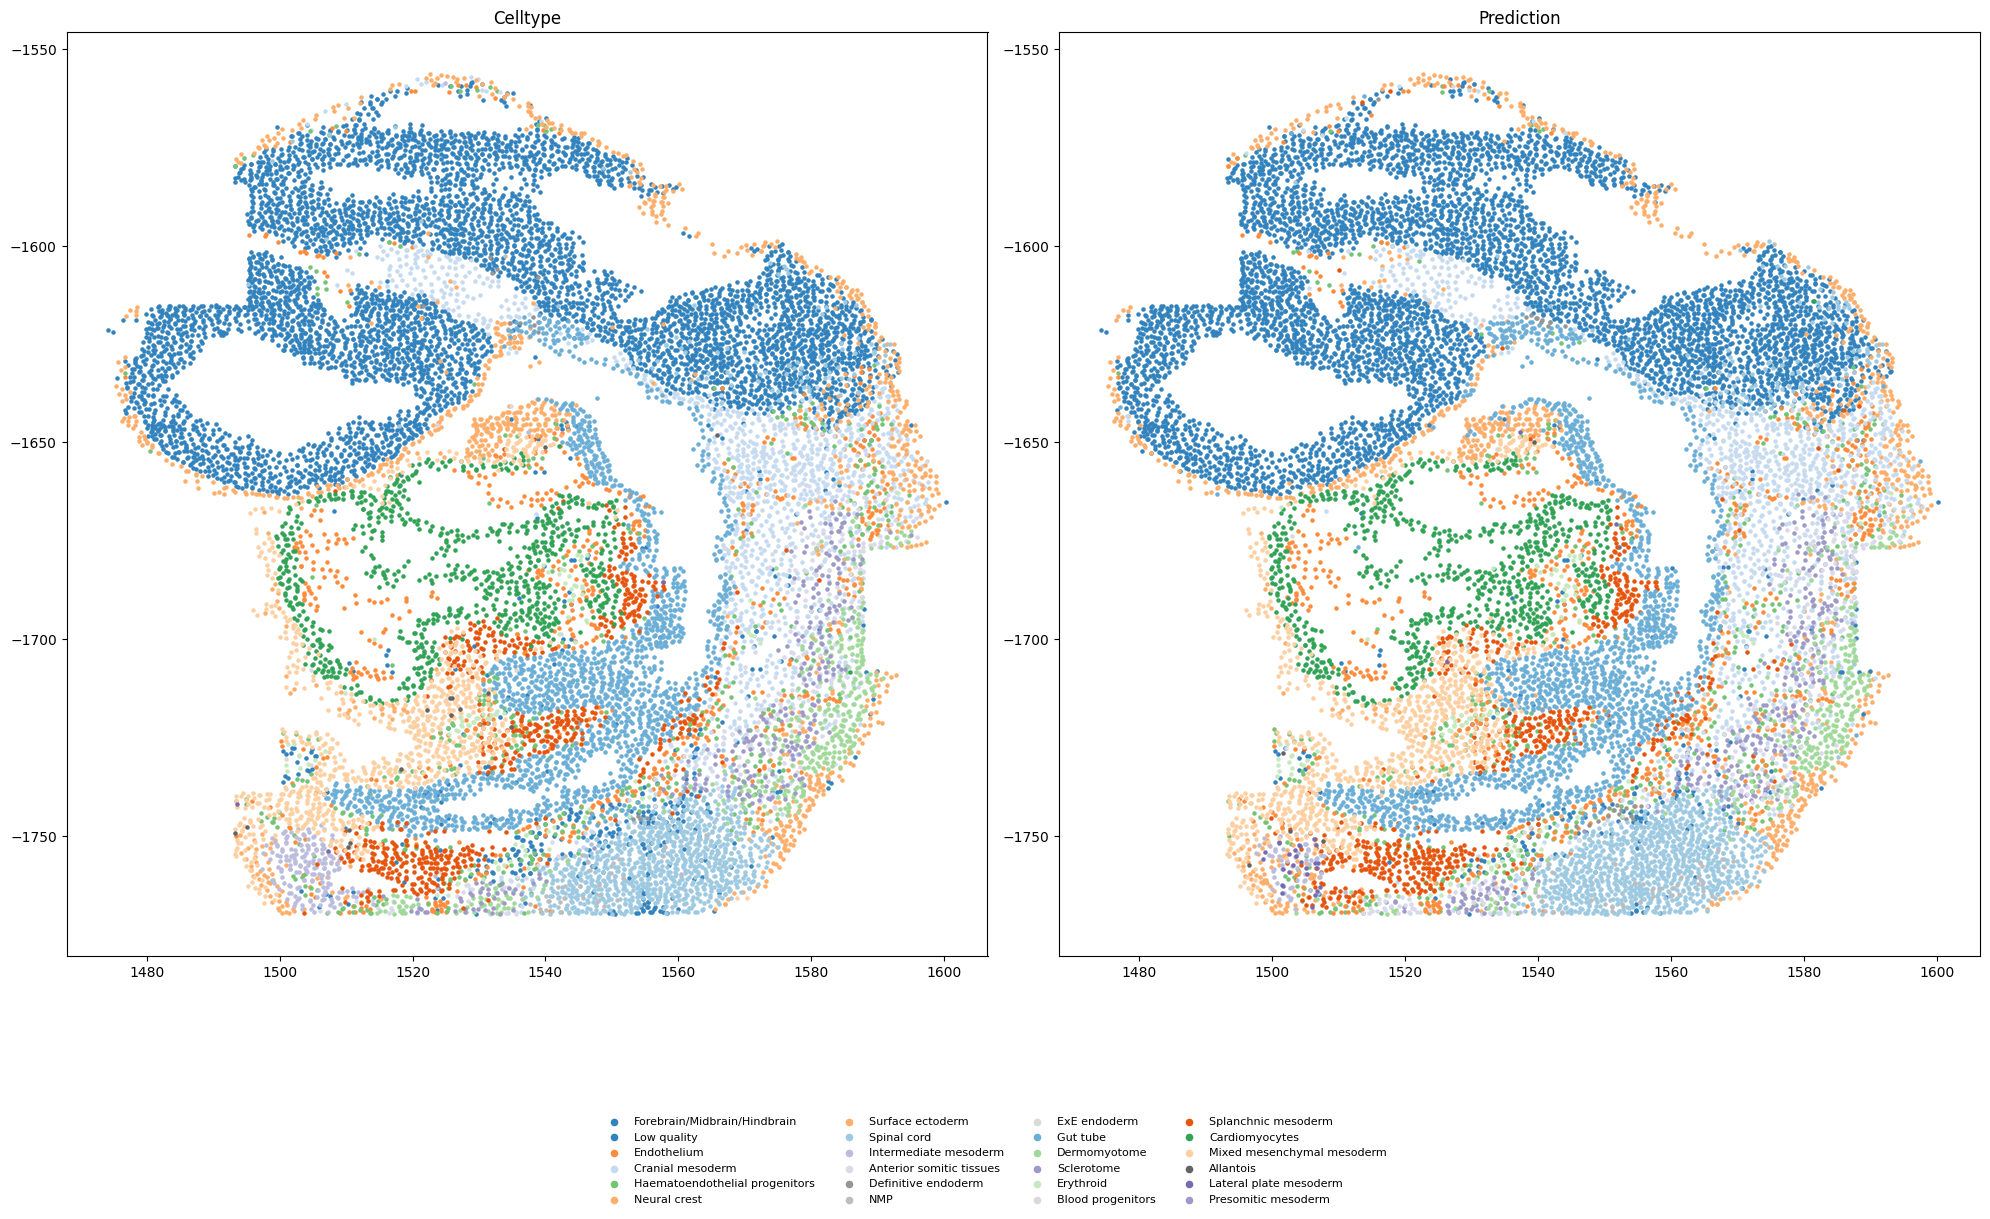

In [8]:
import matplotlib.pyplot as plt

# Use the fixed label order from train_embryo.py.
color_labels = ['Forebrain/Midbrain/Hindbrain', 'Low quality', 'Gut tube', 'Spinal cord', 'Cranial mesoderm', 'Splanchnic mesoderm', 'Endothelium', 'Neural crest', 'Surface ectoderm', 'Mixed mesenchymal mesoderm', 'Cardiomyocytes', 'Haematoendothelial progenitors', 'Dermomyotome', 'Erythroid', 'Lateral plate mesoderm', 'Sclerotome', 'Presomitic mesoderm', 'Intermediate mesoderm', 'Anterior somitic tissues', 'Allantois', 'Definitive endoderm', 'NMP', 'Blood progenitors', 'ExE endoderm']
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].set_title("Prediction")
# One shared legend keeps all 24 labels visible without covering cells.
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
figure.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=4, fontsize=8, markerscale=2, frameon=False)
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


In [9]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD_2,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 116706])
edge_index after merge shape: torch.Size([2, 116873])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


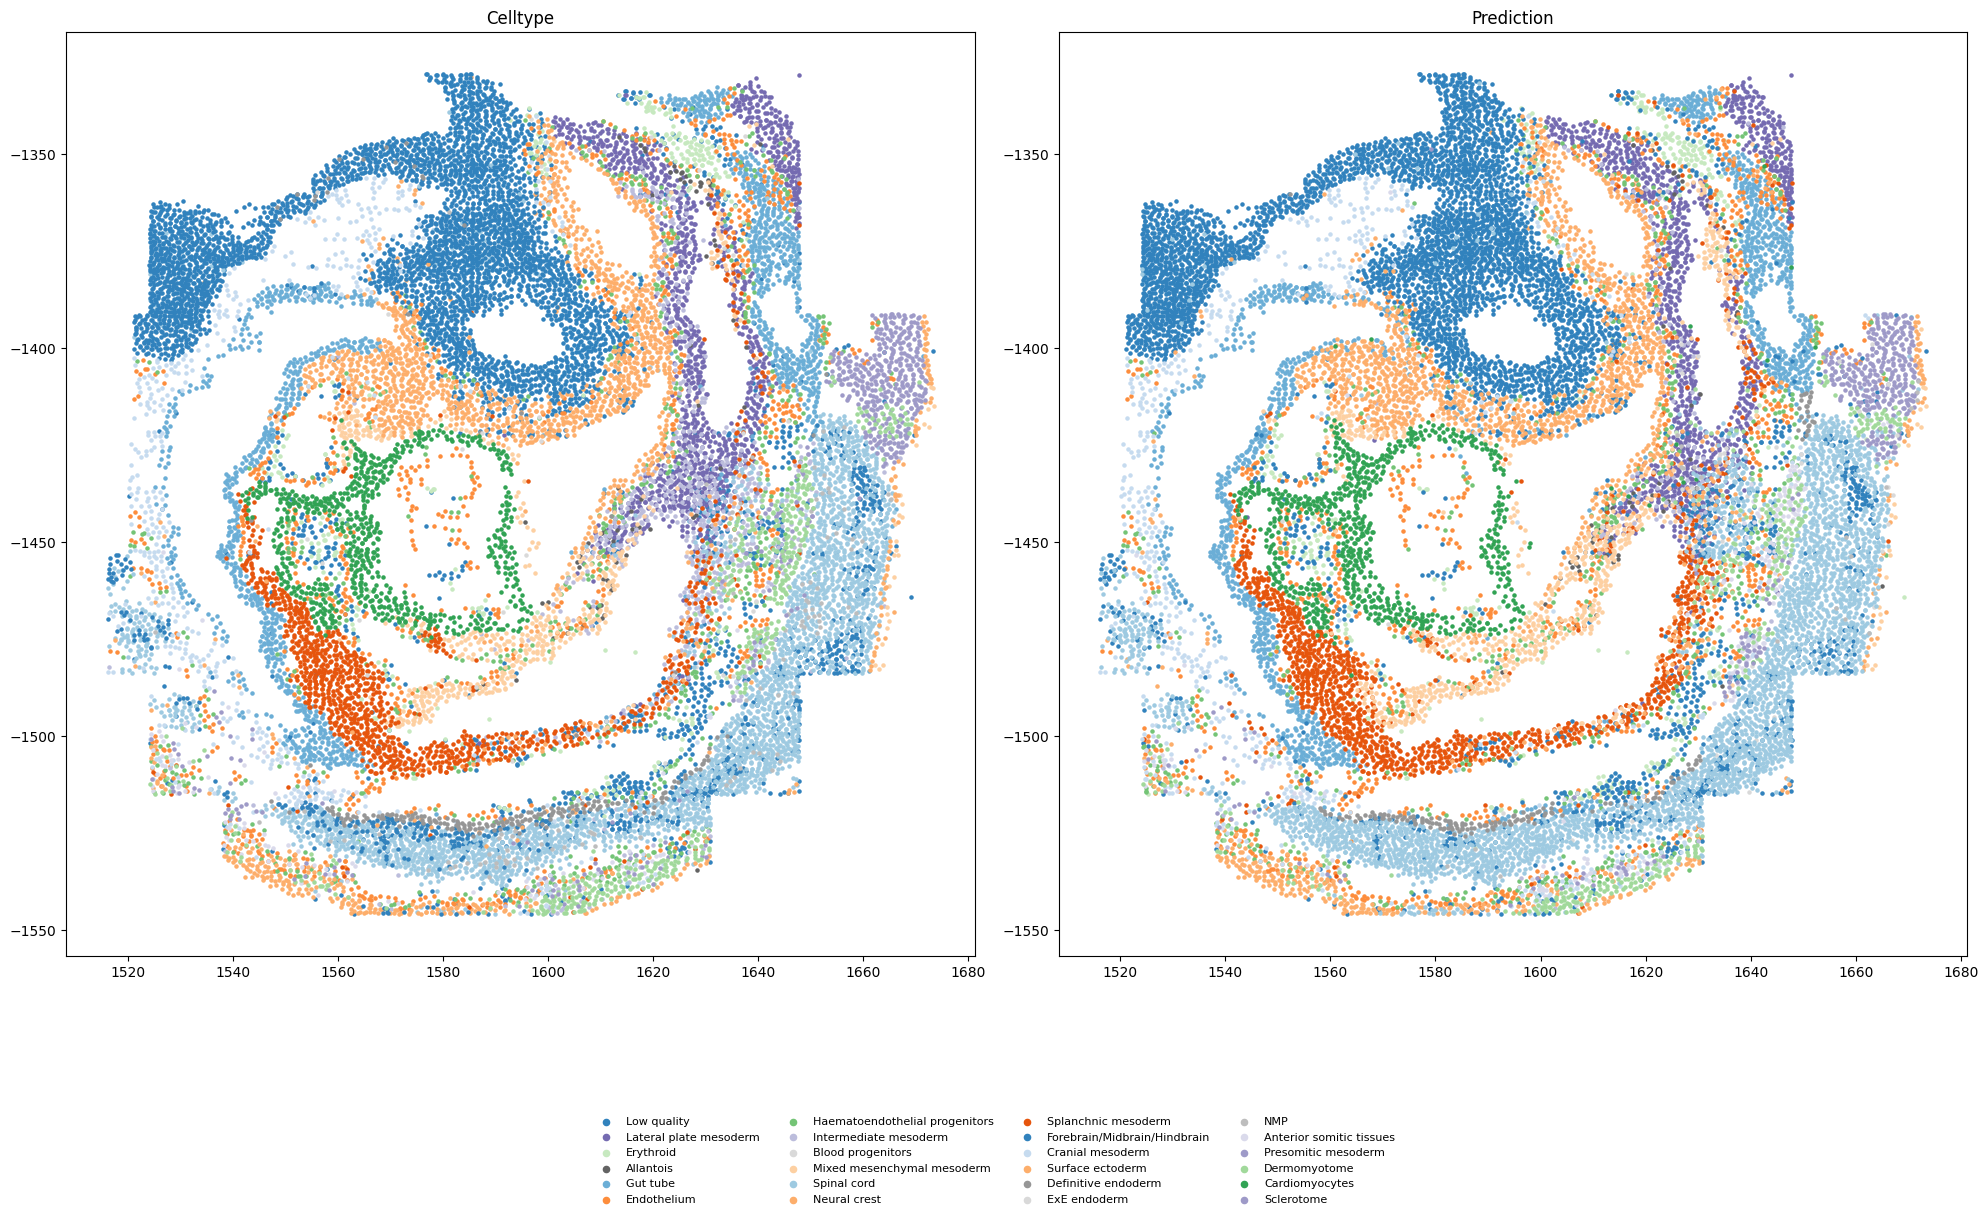

In [10]:
import matplotlib.pyplot as plt

# Use the fixed label order from train_embryo.py.
color_labels = ['Forebrain/Midbrain/Hindbrain', 'Low quality', 'Gut tube', 'Spinal cord', 'Cranial mesoderm', 'Splanchnic mesoderm', 'Endothelium', 'Neural crest', 'Surface ectoderm', 'Mixed mesenchymal mesoderm', 'Cardiomyocytes', 'Haematoendothelial progenitors', 'Dermomyotome', 'Erythroid', 'Lateral plate mesoderm', 'Sclerotome', 'Presomitic mesoderm', 'Intermediate mesoderm', 'Anterior somitic tissues', 'Allantois', 'Definitive endoderm', 'NMP', 'Blood progenitors', 'ExE endoderm']
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].set_title("Prediction")
# One shared legend keeps all 24 labels visible without covering cells.
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
figure.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=4, fontsize=8, markerscale=2, frameon=False)
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


## Notes

- Query genes must match the model gene names and gene order.
- Replace `QUERY_SAMPLE` with the value stored in `adata.obs["batch"]` for the query graph.